# Backtest figures for the paper

Section 6 of the paper asks, looking back, whether buying favourites on the two general-election nights would have
made money: 5 November 2024 and the midterms of 3 November 2026. The bets are those of
`backtest/favourite_backtest.ipynb`, rebuilt here with the same code:
- $100 on the favourite of every US contest with a usable price at the snapshot, held until the market settles;
- Kalshi at the actual asking price plus its taker fee;
- Polymarket at the recorded price plus 1 cent, plus its taker fee from 30 March 2026.

Favourites above 95% and the runoff states are included, as in the backtest notebook.

This notebook makes:
1. the return by price band on each night, next to what the frozen 2024 stretch predicted for the midterms;
2. the rule "buy every favourite priced at or above X%" for every X: total profit and return;
3. every price window with 5-point edges, to show how much the best one depends on the night;
4. a summary table with intervals that resample states.

Everything here looks backwards. None of it was fixed before the vote.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Rectangle

sys.path.insert(0, "../fit")
import midterm_test
import stretch

PRICES = Path("../calendar_and_prices/contest_prices.csv")
CALENDARS = [Path("../calendar_and_prices/contest_calendar.csv"), Path("../calendar_and_prices/midterm_calendar.csv")]
FIGURES, TABLES = Path("figures"), Path("tables")
FIGURES.mkdir(exist_ok=True)
TABLES.mkdir(exist_ok=True)
STAGE = "final" if Path("../fit/results/midterm_test_final.csv").exists() else "preliminary"

STAKE = 100
KALSHI_TAKER = 0.07              # x price x (1 - price) per contract; Kalshi fee schedule effective 7 July 2026
POLYMARKET_TAKER = 0.04          # x price x (1 - price) per share; Polymarket politics taker fee
POLYMARKET_FEES_FROM = "2026-03-30"
POLYMARKET_HALF_SPREAD = 0.01    # Polymarket has a recorded price, not a quote: buying assumed to cost 1 cent more
TRADABLE = {"kept", "drop: favourite above 95% (scaled)"}
PLATFORMS = ["Kalshi", "Polymarket"]
NIGHTS = {"US-2024-11-05": "5 Nov 2024", midterm_test.TEST_DAY: "Midterms 2026"}
NIGHT_NAMES = list(NIGHTS.values())

GENERAL, MIDTERMS = "#2a78d6", "#1baf7a"
COLOUR = {"5 Nov 2024": GENERAL, "Midterms 2026": MIDTERMS}
SURFACE, INK, INK_2, MUTED, GRID, EMPTY = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#f0efec"
RETURNS = LinearSegmentedColormap.from_list("loss_profit", ["#c4471c", "#f3a07a", "#e8e7e3", "#6da7ec", "#184f95"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": INK_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110, "text.parse_math": False,
})


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=220, bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")


def value_grid(ax, axis="y"):
    ax.grid(axis=axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

## The bets

The same construction as section 1 of `backtest/favourite_backtest.ipynb`, for favourites on the two general-election
nights only.

In [2]:
raw = pd.read_csv(PRICES, dtype={"contest_id": str})
raw = raw[(raw["country"] == "United States") & raw["reason"].isin(TRADABLE) & raw["election_key"].isin(NIGHTS)].copy()
a = raw["p_a"] >= raw["p_b"]
bets = pd.DataFrame({
    "platform": raw["platform"].to_numpy(), "contest_id": raw["contest_id"].to_numpy(),
    "title": raw["title"].to_numpy(), "state": raw["state"].fillna("none").to_numpy(),
    "night": raw["election_key"].map(NIGHTS).to_numpy(),
    "price": np.where(a, raw["p_a"], raw["p_b"]),                # scaled, as in the study
    "quote": np.where(a, raw["price_a"], raw["price_b"]),        # the candidate's own price, not scaled
    "spread": np.where(a, raw["spread_a"], raw["spread_b"]),
    "won": np.where(a, raw["a_won"], 1 - raw["a_won"]).astype(int)})
day = raw["election_key"].str.split("-", n=1).str[1].to_numpy()
kalshi = bets["platform"] == "Kalshi"
half_spread = np.where(kalshi, bets["spread"].fillna(0.02) / 2, POLYMARKET_HALF_SPREAD)
bets["paid"] = np.minimum(bets["quote"] + half_spread, 1.0)
rate = np.where(kalshi, KALSHI_TAKER, np.where(day >= POLYMARKET_FEES_FROM, POLYMARKET_TAKER, 0.0))
bets["all_in"] = bets["paid"] + rate * bets["paid"] * (1 - bets["paid"])
bets = bets[bets["all_in"] < 1].reset_index(drop=True)
bets["return"] = bets["won"] / bets["all_in"] - 1
bets["profit"] = STAKE * bets["return"]

# Check against the backtest notebook's results, where those exist.
check = Path(f"../backtest/results/backtest_{STAGE}_general_nights.csv")
if check.exists():
    ref = pd.read_csv(check)
    ref = ref[ref["day"].isin(["2024-11-05", "2026-11-03"])]
    for _, r in ref.iterrows():
        part = bets[(bets["platform"] == r["platform"]) & (bets["night"] == NIGHTS["US-" + r["day"]])]
        assert len(part) == r["bets"] and np.isclose(part["profit"].sum(), r["profit"]), (r["platform"], r["day"])
bets.groupby(["platform", "night"]).agg(bets=("won", "size"), upsets=("won", lambda w: int((1 - w).sum())),
                                        profit=("profit", "sum")).round(1)

bets  upsets  profit
platform   night                              
Kalshi     5 Nov 2024       97      12   339.3
           Midterms 2026   547      36   480.6
Polymarket 5 Nov 2024       91       3   663.2
           Midterms 2026   419      20  1256.3

In [3]:
def summarise(part, seed=stretch.SEED):
    """Bets, upsets, profit and return, with a 95% interval for the return from resampling states."""
    if len(part) == 0:
        return {"bets": 0}
    rng = np.random.default_rng(seed)
    states = part["state"].to_numpy()
    units = np.unique(states)
    profit = np.array([part["profit"].to_numpy()[states == u].sum() for u in units])
    count = np.array([(states == u).sum() for u in units])
    draws = rng.integers(0, len(units), (stretch.RESAMPLES, len(units)))
    boot = profit[draws].sum(1) / (STAKE * count[draws].sum(1))
    return {"bets": len(part), "states": len(units), "upsets": int((1 - part["won"]).sum()),
            "profit, $": part["profit"].sum(), "return": part["profit"].sum() / (STAKE * len(part)),
            "low": np.quantile(boot, 0.025), "high": np.quantile(boot, 0.975),
            "share of resamples losing": (boot < 0).mean()}


def window(part, low, high):
    """Favourites priced from `low` up to, but not including, `high` (a top edge of 1 includes 100%)."""
    return part[(part["price"] >= low) & ((part["price"] < high) | (high >= 1))]

## 1. Return by price band

Five-point bands from 50% to 95%, and one band for every favourite above 95%. Bars are each night's return per $100
after costs; the number above or below is the number of bets. Bars beyond ±40% are cut, and their value is written at
the end.

The black marks show what the frozen 2024 stretch predicted for the midterm bets in each band: the chance it gives
each favourite, divided by what the bet cost, minus one. The stretch was fixed before the vote, so for the midterms
this is a genuine forecast.

,platform,night,band,bets,upsets,"profit, $",return,predicted by the frozen 2024 stretch
0,Kalshi,5 Nov 2024,50–55,6,3,-60.922,-0.102,NaN
1,Kalshi,5 Nov 2024,55–60,7,2,132.743,0.190,NaN
2,Kalshi,5 Nov 2024,60–65,9,4,-128.400,-0.143,NaN
3,Kalshi,5 Nov 2024,65–70,7,2,-4.535,-0.006,NaN
4,Kalshi,5 Nov 2024,70–75,4,1,1.658,0.004,NaN
5,Kalshi,5 Nov 2024,75–80,4,0,100.658,0.252,NaN
6,Kalshi,5 Nov 2024,80–85,6,0,105.929,0.177,NaN
7,Kalshi,5 Nov 2024,85–90,6,0,70.437,0.117,NaN
8,Kalshi,5 Nov 2024,90–95,9,0,49.341,0.055,NaN
9,Kalshi,5 Nov 2024,95+,39,0,72.410,0.019,NaN


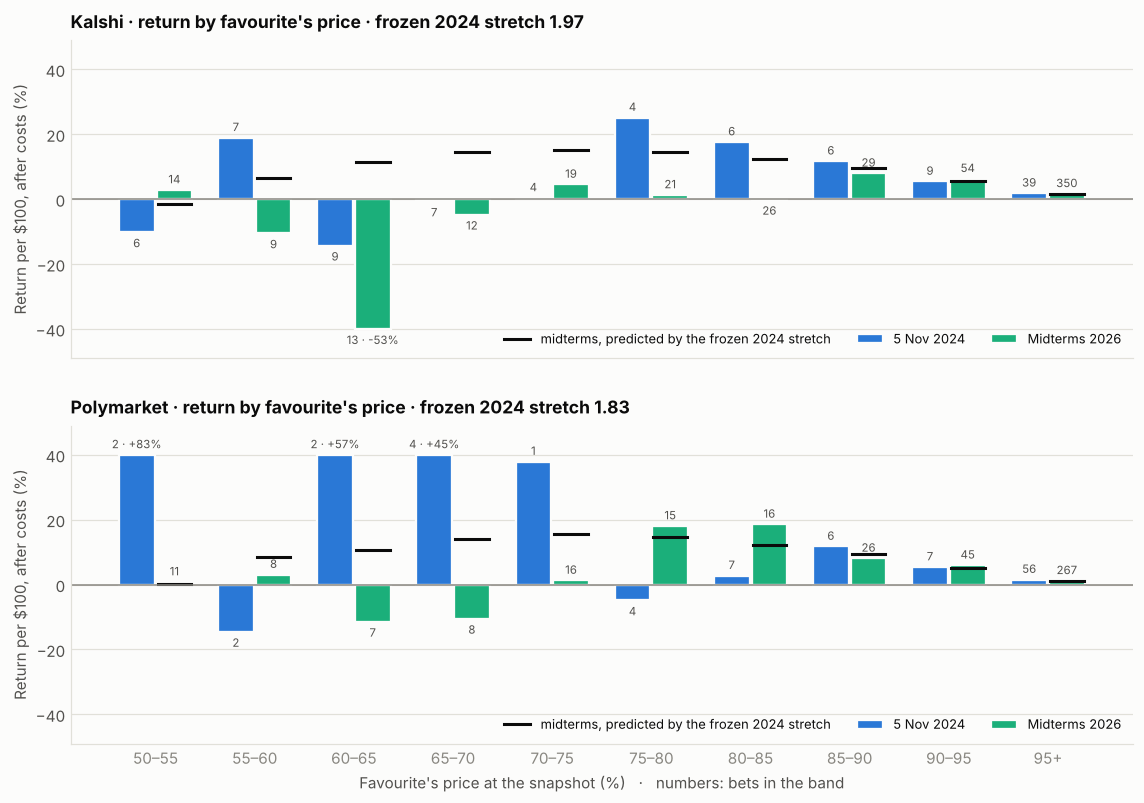

In [4]:
EDGES = [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 1.0]
LABELS = [f"{int(100 * lo)}–{int(100 * hi)}" for lo, hi in zip(EDGES[:-2], EDGES[1:-1])] + ["95+"]
CUT = 40

band_rows = []
fig, axes = plt.subplots(2, 1, figsize=(10.5, 7.4), sharex=True)
for ax, p in zip(axes, PLATFORMS):
    b0 = midterm_test.BASELINE_B[p]
    for k, night in enumerate(NIGHT_NAMES):
        part = bets[(bets["platform"] == p) & (bets["night"] == night)]
        for i, (lo, hi) in enumerate(zip(EDGES[:-1], EDGES[1:])):
            sub = window(part, lo, hi)
            row = {"platform": p, "night": night, "band": LABELS[i], "bets": len(sub),
                   "upsets": int((1 - sub["won"]).sum()), "profit, $": sub["profit"].sum(),
                   "return": sub["profit"].sum() / (STAKE * len(sub)) if len(sub) else np.nan}
            if night == "Midterms 2026" and len(sub):
                row["predicted by the frozen 2024 stretch"] = np.mean(stretch.stretch(sub["price"], b0) / sub["all_in"] - 1)
            band_rows.append(row)
            if not len(sub):
                continue
            x = i + (k - 0.5) * 0.38
            value = 100 * row["return"]
            shown = float(np.clip(value, -CUT, CUT))
            ax.bar(x, shown, width=0.36, color=COLOUR[night], edgecolor=SURFACE, linewidth=1.5,
                   label=night if i == 0 else None)
            note = f"{len(sub)}" if abs(value) <= CUT else f"{len(sub)} · {value:+.0f}%"
            ax.text(x, shown + (1.2 if shown >= 0 else -1.2), note, ha="center", va="bottom" if shown >= 0 else "top",
                    fontsize=7.5, color=INK_2)
            if night == "Midterms 2026":
                predicted = 100 * row["predicted by the frozen 2024 stretch"]
                ax.plot([x - 0.17, x + 0.17], [predicted, predicted], color=INK, linewidth=2,
                        label="midterms, predicted by the frozen 2024 stretch" if i == 0 else None)
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.set_ylim(-CUT - 9, CUT + 9)
    ax.set_ylabel("Return per $100, after costs (%)")
    ax.set_title(f"{p} · return by favourite's price · frozen 2024 stretch {b0:.2f}", pad=8)
    value_grid(ax)
    ax.legend(loc="lower right", fontsize=8.5, ncol=3)
axes[1].set_xticks(range(len(LABELS)), LABELS)
axes[1].set_xlabel("Favourite's price at the snapshot (%)   ·   numbers: bets in the band")
fig.tight_layout(h_pad=2.5)
save(fig, "bt_bands")
band_table = pd.DataFrame(band_rows)
band_table.to_csv(TABLES / f"bt_bands_{STAGE}.csv", index=False)
band_table.round(3)

## 2. Buying every favourite above a threshold

For every threshold from 50% to 95%, the rule buys every favourite priced at or above it. Top: total profit. Bottom:
return per $100. Raising the threshold drops the close races, which lost money on the midterms, but also drops bets
that would have paid. Total profit peaks where those two pull equally.

platform      Kalshi               Polymarket              
night     5 Nov 2024 Midterms 2026 5 Nov 2024 Midterms 2026
threshold                                                  
0.50           339.0         481.0      663.0        1256.0
0.55           400.0         441.0      498.0        1247.0
0.60           267.0         535.0      527.0        1222.0
0.65           396.0        1218.0      413.0        1302.0
0.70           400.0        1275.0      234.0        1386.0
0.75           399.0        1188.0      197.0        1366.0
0.80           298.0        1160.0      216.0        1095.0
0.85           192.0        1164.0      196.0         797.0
0.90           122.0         932.0      126.0         587.0
0.95            72.0         590.0       88.0         318.0

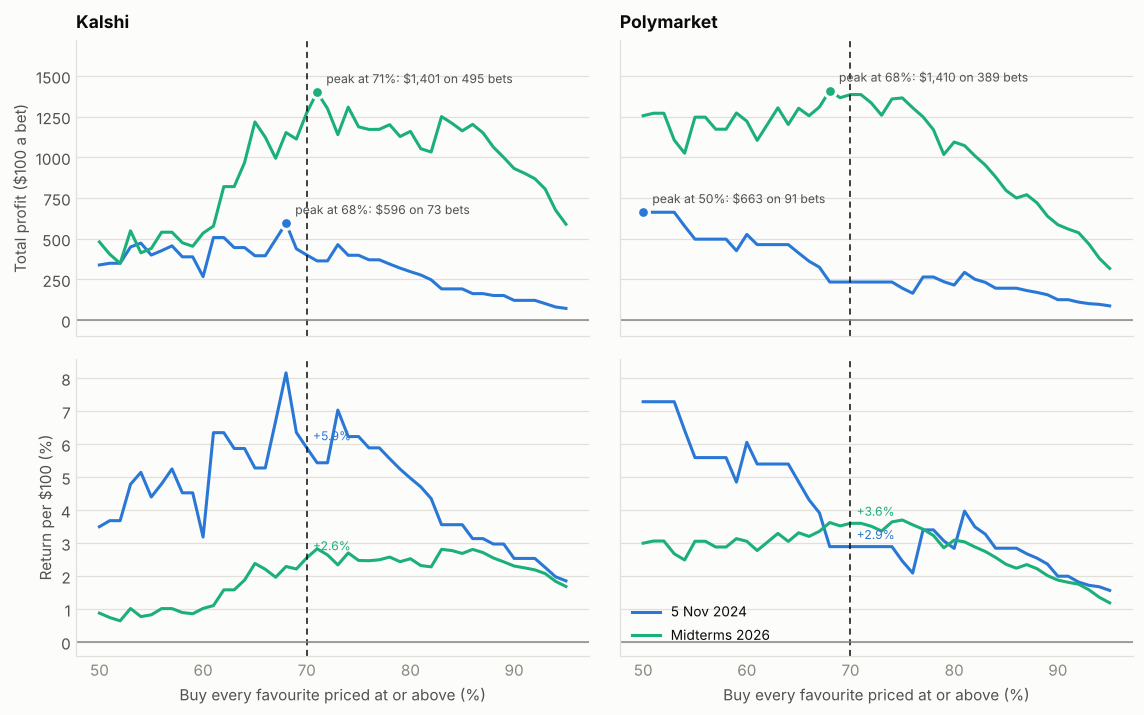

In [5]:
THRESHOLDS = np.round(np.arange(0.50, 0.951, 0.01), 2)
rule_rows = []
for p in PLATFORMS:
    for night in NIGHT_NAMES:
        part = bets[(bets["platform"] == p) & (bets["night"] == night)]
        for t in THRESHOLDS:
            sub = part[part["price"] >= t]
            rule_rows.append({"platform": p, "night": night, "threshold": t, "bets": len(sub),
                              "profit, $": sub["profit"].sum(), "return": sub["profit"].sum() / (STAKE * len(sub))})
rules = pd.DataFrame(rule_rows)
rules.to_csv(TABLES / f"bt_thresholds_{STAGE}.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.6), sharex=True, sharey="row")
for col, p in enumerate(PLATFORMS):
    for night in NIGHT_NAMES:
        r = rules[(rules["platform"] == p) & (rules["night"] == night)]
        x = 100 * r["threshold"]
        axes[0, col].plot(x, r["profit, $"], color=COLOUR[night], linewidth=2, label=night)
        axes[1, col].plot(x, 100 * r["return"], color=COLOUR[night], linewidth=2, label=night)
        best = r.loc[r["profit, $"].idxmax()]
        axes[0, col].scatter([100 * best["threshold"]], [best["profit, $"]], s=60, color=COLOUR[night], zorder=3,
                             edgecolor=SURFACE, linewidth=2)
        axes[0, col].annotate(f"peak at {100 * best['threshold']:.0f}%: ${best['profit, $']:,.0f} on {best['bets']} bets",
                              (100 * best["threshold"], best["profit, $"]), xytext=(6, 6), textcoords="offset points",
                              fontsize=8, color=INK_2)
        at70 = r[np.isclose(r["threshold"], 0.70)].iloc[0]
        axes[1, col].annotate(f"{100 * at70['return']:+.1f}%", (70, 100 * at70["return"]), xytext=(4, 5),
                              textcoords="offset points", fontsize=8, color=COLOUR[night])
    for row in range(2):
        ax = axes[row, col]
        ax.axvline(70, color=INK, linewidth=1, linestyle=(0, (4, 3)))
        ax.axhline(0, color=MUTED, linewidth=1)
        value_grid(ax)
    axes[0, col].set_title(f"{p}", pad=8)
    axes[1, col].set_xlabel("Buy every favourite priced at or above (%)")
axes[0, 0].set_ylabel("Total profit ($100 a bet)")
axes[1, 0].set_ylabel("Return per $100 (%)")
axes[1, 1].legend(loc="lower left", fontsize=9)
for ax in axes[0]:
    ax.set_ylim(bottom=min(-100, rules["profit, $"].min() - 50), top=rules["profit, $"].max() * 1.22)
fig.tight_layout(h_pad=1.5, w_pad=2)
save(fig, "bt_thresholds")
rules[np.isclose(rules["threshold"] * 100 % 5, 0)].pivot_table(index="threshold", columns=["platform", "night"],
                                                                 values="profit, $").round(0)

## 3. Every price window

Each cell is one strategy: buy every favourite priced from the row's value up to the column's value (5-point steps,
the last column includes everything up to 100%). The colour is the return per $100; cells with fewer than five bets are
blank. The solid outline marks the best window on that night, the dashed outline 85–90%. That is 55 windows per
platform and night, so the best one is chosen from a large menu.

/tmp/ipykernel_995/3574126083.py:51: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0.06, 1, 1), h_pad=2, w_pad=2)


,platform,night,from,to,bets,return
41,Kalshi,5 Nov 2024,0.75,0.85,10,0.206587
104,Kalshi,Midterms 2026,0.85,0.90,29,0.079906
130,Polymarket,5 Nov 2024,0.60,0.70,6,0.487320
210,Polymarket,Midterms 2026,0.80,0.85,16,0.185765


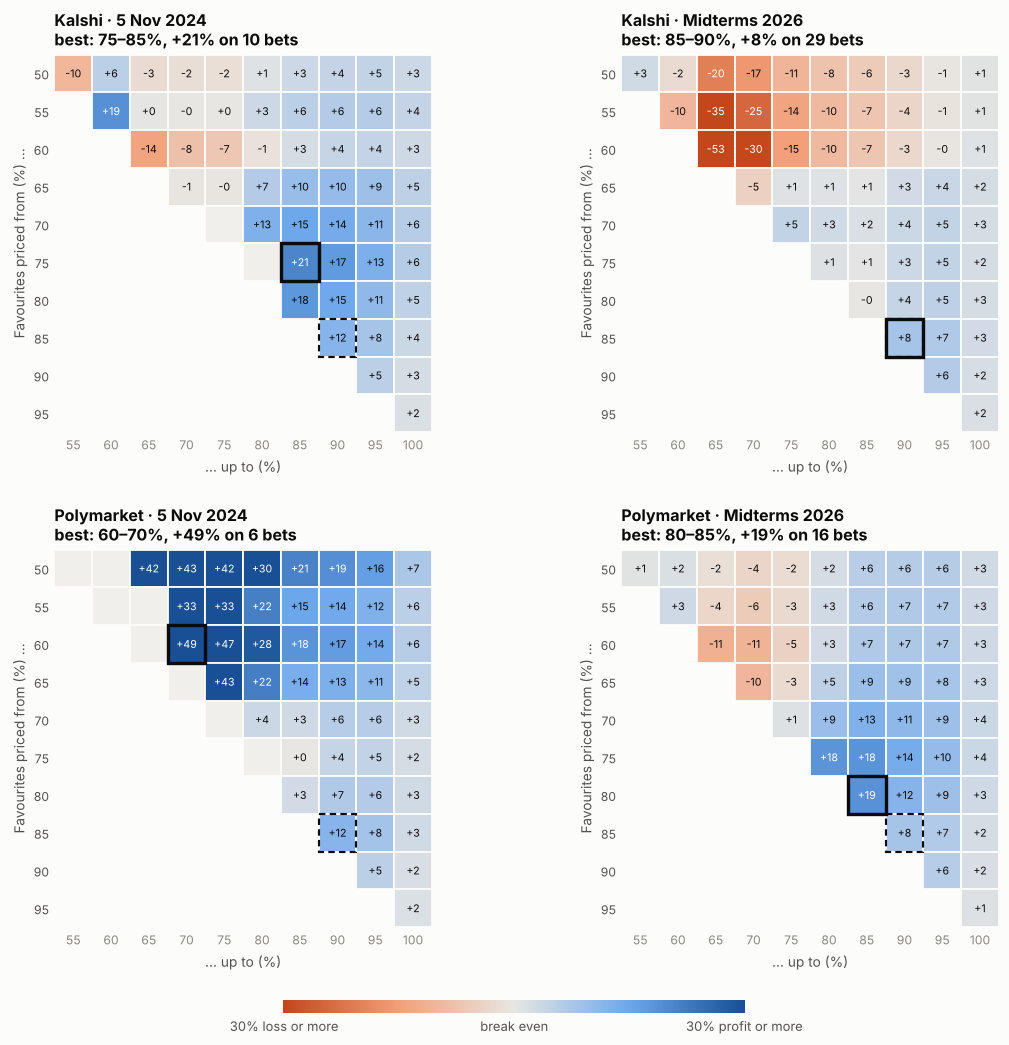

In [6]:
STEPS = np.round(np.arange(0.50, 1.0001, 0.05), 2)
MIN_BETS = 5
grid_rows = []
fig, axes = plt.subplots(2, 2, figsize=(10.5, 9.6))
norm = TwoSlopeNorm(vcenter=0, vmin=-30, vmax=30)
for r_, p in enumerate(PLATFORMS):
    for c_, night in enumerate(NIGHT_NAMES):
        ax = axes[r_, c_]
        part = bets[(bets["platform"] == p) & (bets["night"] == night)]
        best = None
        for i, lo in enumerate(STEPS[:-1]):
            for j, hi in enumerate(STEPS[1:], start=1):
                if hi <= lo:
                    continue
                sub = window(part, lo, hi)
                ret = sub["profit"].sum() / (STAKE * len(sub)) if len(sub) else np.nan
                grid_rows.append({"platform": p, "night": night, "from": lo, "to": hi, "bets": len(sub), "return": ret})
                x, y = j - 1, i
                if len(sub) < MIN_BETS:
                    ax.add_patch(Rectangle((x, y), 1, 1, facecolor=EMPTY, edgecolor=SURFACE, linewidth=1.2))
                    continue
                ax.add_patch(Rectangle((x, y), 1, 1, facecolor=RETURNS(norm(100 * ret)), edgecolor=SURFACE, linewidth=1.2))
                dark = abs(100 * ret) > 18
                ax.text(x + 0.5, y + 0.5, f"{100 * ret:+.0f}", ha="center", va="center", fontsize=7,
                        color="white" if dark else INK)
                if best is None or ret > best[0]:
                    best = (ret, x, y, lo, hi, len(sub))
        ret, x, y, lo, hi, n = best
        ax.add_patch(Rectangle((x, y), 1, 1, fill=False, edgecolor=INK, linewidth=2.2))
        i85, j90 = list(STEPS).index(0.85), list(STEPS).index(0.90)
        ax.add_patch(Rectangle((j90 - 1, i85), 1, 1, fill=False, edgecolor=INK, linewidth=1.4, linestyle=(0, (3, 2))))
        ax.set_xlim(0, len(STEPS) - 1)
        ax.set_ylim(len(STEPS) - 1, 0)
        ax.set_aspect("equal")
        ax.set_xticks(np.arange(len(STEPS) - 1) + 0.5, [f"{int(100 * h)}" for h in STEPS[1:]], fontsize=8)
        ax.set_yticks(np.arange(len(STEPS) - 1) + 0.5, [f"{int(100 * l)}" for l in STEPS[:-1]], fontsize=8)
        ax.tick_params(length=0)
        for side in ax.spines.values():
            side.set_visible(False)
        ax.set_title(f"{p} · {night}\nbest: {int(100 * lo)}–{int(100 * hi)}%, {100 * ret:+.0f}% on {n} bets",
                     fontsize=10.5, pad=6)
        ax.set_xlabel("... up to (%)", fontsize=9)
        ax.set_ylabel("Favourites priced from (%) ...", fontsize=9)
key = fig.add_axes([0.3, 0.035, 0.4, 0.012])
key.imshow(np.linspace(0, 1, 256)[None, :], aspect="auto", cmap=RETURNS)
key.set_yticks([])
key.set_xticks([0, 127.5, 255], ["30% loss or more", "break even", "30% profit or more"])
key.tick_params(length=0, labelsize=8.5, colors=INK_2)
for side in key.spines.values():
    side.set_visible(False)
fig.tight_layout(rect=(0, 0.06, 1, 1), h_pad=2, w_pad=2)
save(fig, "bt_windows")
windows = pd.DataFrame(grid_rows)
windows.to_csv(TABLES / f"bt_windows_{STAGE}.csv", index=False)
best_windows = (windows[windows["bets"] >= MIN_BETS].sort_values("return", ascending=False)
                .groupby(["platform", "night"]).head(1).sort_values(["platform", "night"]))
best_windows

## 4. Summary table

For each platform and night: every favourite, every favourite at or above 70%, the 85–90% band, and the best window
in hindsight. The last row of each platform takes the best 2024 window and applies it to the midterms, which is what
a trader shopping on 2024 would have done. Intervals resample states.

In [7]:
rows = []
for p in PLATFORMS:
    picks = {night: best_windows[(best_windows["platform"] == p) & (best_windows["night"] == night)].iloc[0]
             for night in NIGHT_NAMES}
    for night in NIGHT_NAMES:
        part = bets[(bets["platform"] == p) & (bets["night"] == night)]
        best = picks[night]
        for rule, sub in (("every favourite", part), ("at or above 70%", part[part["price"] >= 0.70]),
                          ("85–90%", window(part, 0.85, 0.90)),
                          (f"best in hindsight ({int(100 * best['from'])}–{int(100 * best['to'])}%)",
                           window(part, best["from"], best["to"]))):
            rows.append({"platform": p, "night": night, "rule": rule, **summarise(sub)})
    best24 = picks["5 Nov 2024"]
    part = bets[(bets["platform"] == p) & (bets["night"] == "Midterms 2026")]
    rows.append({"platform": p, "night": "Midterms 2026",
                 "rule": f"best 2024 window ({int(100 * best24['from'])}–{int(100 * best24['to'])}%) applied",
                 **summarise(window(part, best24["from"], best24["to"]))})
summary = pd.DataFrame(rows)
summary.to_csv(TABLES / f"bt_summary_{STAGE}.csv", index=False)
summary.round(3)

,platform,night,rule,bets,states,upsets,"profit, $",return,low,high,share of resamples losing
0,Kalshi,5 Nov 2024,every favourite,97,49,12,339.319,0.035,-0.059,0.128,0.204
1,Kalshi,5 Nov 2024,at or above 70%,68,48,1,400.433,0.059,0.015,0.090,0.008
2,Kalshi,5 Nov 2024,85–90%,6,5,0,70.437,0.117,0.106,0.127,0.000
3,Kalshi,5 Nov 2024,best in hindsight (75–85%),10,10,0,206.587,0.207,0.174,0.235,0.000
4,Kalshi,Midterms 2026,every favourite,547,49,36,480.642,0.009,-0.035,0.050,0.344
5,Kalshi,Midterms 2026,at or above 70%,499,49,13,1274.806,0.026,-0.004,0.050,0.046
6,Kalshi,Midterms 2026,85–90%,29,16,1,231.727,0.080,-0.001,0.125,0.026
7,Kalshi,Midterms 2026,best in hindsight (85–90%),29,16,1,231.727,0.080,-0.001,0.125,0.026
8,Kalshi,Midterms 2026,best 2024 window (75–85%) applied,47,22,8,24.437,0.005,-0.273,0.205,0.446
9,Polymarket,5 Nov 2024,every favourite,91,49,3,663.152,0.073,0.015,0.129,0.008
